# NESG: within-property evaluation of existing probes

**Let the uncontrolled notebook finish and inspect its results first. Then run this notebook.**
Keep all **33 layers**: the expensive probe fitting has already been done. This notebook recalculates
metrics from saved validation predictions inside biological subsets. It neither fits new probes nor
runs protein sequences through ESM. A CPU runtime is sufficient.

| Question | Evaluation |
|---|---|
| Is soluble recovery still distinguishable within a hydrophobicity range? | Same global solubility probe, evaluated separately in training-defined ranges |
| What about charge, length, aggregation or APR burden? | Restrict one property at a time using the same fixed rule |
| Is solubility distinguishable within a family? | Same global solubility probe within each observed Pfam family; support shown explicitly |
| Are other properties still decodable in these subsets? | Reuse continuous-property predictions within ranges/families and family-membership predictions within numeric ranges |

There is **no prediction of the defining family's membership inside its own family**, where that target
is constant. No joint matching, residualization, retraining on subsets, SAE analysis, interventions or
reserved-test evaluation is performed. Broad range restriction is an approximate restriction, not
proof that a confounder has been removed. The canonical heterogeneous dataset is unchanged.

**Status:** input/support and engineering checks are performed locally. Actual all-layer conditional
performance appears only after this notebook runs against your completed private HF results.
The current uncontrolled notebook and its checkpoints are preserved.

## 1. Locate the project and copy only changed inputs

Change `PROJECT_ROOT` only if your Drive project is in a different location.
No credential files, full-map tensors or reserved-test files are copied.

In [1]:
from pathlib import Path
import hashlib, json, os, shutil, subprocess, sys, venv
from google.colab import drive

if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/plm-property-interpretability')
source = PROJECT_ROOT / 'nesg_primary/esm_layer_probing'
work = Path('/content/nesg_within_eval_code')
required = [
    'common.py', 'extract.py', 'hf_storage.py', 'save_full_maps.py',
    'probe.py', 'plot_train_validation.py', 'run_layerwise_auroc.py',
    'protocol.json', 'data/extraction_manifest.tsv',
    'data/input_integrity.json', 'data/local_labels.tsv',
    'within_property_evaluation.py', 'run_within_property.py', 'property_inputs.py', 'property_probes.py', 'property_report.py', 'run_property_probes.py',
    'data/pfam_memberships.tsv', 'data/uncontrolled/properties.tsv',
    'data/uncontrolled/family_catalog.tsv', 'data/uncontrolled/protocol.json',
    'data/uncontrolled/coverage.tsv', 'data/uncontrolled/integrity.json',
]
missing = [name for name in required if not (source / name).is_file()]
if missing:
    raise FileNotFoundError(f'Check PROJECT_ROOT and Drive sync. Missing: {missing}')
changed = 0
for name in required:
    src, dst = source / name, work / name
    dst.parent.mkdir(parents=True, exist_ok=True)
    digest = hashlib.sha256(src.read_bytes()).digest()
    if not dst.is_file() or hashlib.sha256(dst.read_bytes()).digest() != digest:
        shutil.copyfile(src, dst)
        changed += 1
    assert hashlib.sha256(dst.read_bytes()).digest() == digest
os.chdir(work)
print(f'Updated {changed} code/input files; unchanged files reused.')

Mounted at /content/drive
Updated 23 code/input files; unchanged files reused.


## 2. Prepare or reuse the CPU probing environment

Reuse the extraction interpreter if it still exists. Otherwise create a small
separate environment inheriting Colab's numerical stack. Only missing probing
packages are installed as prebuilt wheels; there is no CUDA preflight, ESM
download or PyTorch installation. Package versions are recorded in the results.

In [2]:
import shlex
from IPython.utils.process import system

os.environ.update(USE_TORCH='1', USE_TF='0', USE_FLAX='0', PYTHONNOUSERSITE='1', MPLBACKEND='Agg')
EVALUATION_PYTHON = Path('/content/nesg_esm_env/bin/python')
if not EVALUATION_PYTHON.is_file():
    environment = Path('/content/nesg_probe_env')
    EVALUATION_PYTHON = environment / 'bin/python'
    if not EVALUATION_PYTHON.is_file():
        venv.EnvBuilder(system_site_packages=True, with_pip=False).create(environment)

def run_stage1(*arguments):
    status = system(shlex.join([str(EVALUATION_PYTHON), '-u', *map(str, arguments)]))
    if status != 0:
        raise RuntimeError(f'Command stopped (exit {status}). See the output above.')

run_stage1('run_layerwise_auroc.py', '--setup-only')

Installing only probing/plotting packages: ['huggingface-hub==0.36.0', 'scipy==1.15.3', 'scikit-learn==1.7.2', 'joblib==1.5.2', 'threadpoolctl==3.6.0', 'matplotlib==3.10.7']
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 3.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 24.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 42.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 40.8 MB/s  0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Not uninstalling threadpoolctl at /usr/local/lib/python3.13/dist-packages, outside environment /content/nesg_probe_env
    Can't uninstall 'threadpoolctl'. No files were found to uninstall.
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Not uninstalling scipy at /usr/local/lib/python3.13/dist-packages, outside environment /content/nesg_probe_env
    Can't uninstall 'scipy'. No files were found 

## 3. Authenticate for saved probe results

Use the existing private HF repository and `HF_TOKEN_PLM` Colab Secret. The next stage downloads
saved probe checkpoints only when they are not already available in this runtime. The checkpoint
archives contain predictions and fitted-probe files; only prediction tables are extracted for use.
No ESM weights, pooled activations or residue maps are downloaded. No repository is created.

In [3]:
from google.colab import userdata
try:
    secret = userdata.get('HF_TOKEN_PLM')
except Exception:
    raise RuntimeError('Enable notebook access to HF_TOKEN_PLM in Colab Secrets.') from None
if not secret:
    raise RuntimeError('HF_TOKEN_PLM is missing from Colab Secrets.')
os.environ['HF_TOKEN_PLM'] = secret
del secret
DESTINATION_REPO = 'PLM-Interp/nesg-esm2-layerwise'
print('Configured private HF destination for saved probe predictions only.')

Configured private HF destination for saved probe predictions only.


## 4. Define restrictions without using probe performance

For each continuous descriptor, the four cut points are training-only 20th/40th/60th/80th percentiles.
Tied boundaries are collapsed; lower bounds are inclusive, upper bounds exclusive, and the outer
intervals extend to infinity. Missing descriptors are never imputed. These are **one-property-at-a-time**
restrictions; other biological properties remain heterogeneous.

Families come from the existing all-GA Pfam assignments observed in training. No ≥3/≥5 training-solubility
threshold is imposed because no new within-family models are being fitted. Support tables include every
training-observed family. Point estimates require at least two validation proteins and, for AUROC/AP,
both labels. Singleton/single-class families remain explicitly unsupported. Proteins may appear in
several distinct family analyses but are counted only once within each family.

The noncompeting-assignment sensitivity removes flagged memberships only for that family analysis;
it does not change the primary cohort. Both variants retain their own denominators.

In [4]:
run_stage1('-c', r'''
from property_inputs import load_inputs
from within_property_evaluation import plan
d,p,m,c=load_inputs()
targets,jobs,support,edges,families=plan(d,p,m,c)
print('Frozen split sizes:', d.split.value_counts().to_dict())
print('Training-only cut points:')
for name, cuts in edges.items(): print(name, cuts)
print('\nSolubility support (not performance):')
print(support[support.target.eq('solubility')].groupby(['kind','variant','status']).size().to_string())
print('\nNo prediction files loaded; no fitting; reserved test untouched.')
''')

Frozen split sizes: {'train': 2361, 'validation': 691}
Training-only cut points:
hydrophobicity [-0.49714982317007816, -0.3318971418501725, -0.20980563847429526, -0.06824668227946902]
charge_proxy [-0.0427807486631016, -0.024287567312605618, -0.008695652173913, 0.012215032354405145]
log_length [4.882801922586371, 5.241747015059643, 5.54907608489522, 5.899897353582492]
aggregation_Na4vSS [-11.8, -6.5, -3.0, 1.1]
apr_fraction [0.24045764362220057, 0.3000896860986547, 0.34916373708320014, 0.4078535839376449]

Solubility support (not performance):
kind     variant             status                 
family   all_ga              estimable                  46
                             single_validation_class    36
         noncompeting        estimable                  20
                             single_validation_class    15
overall  all                 estimable                   1
range    training_quantiles  estimable                  25

No prediction files loaded; no fitting; re

## 5. Evaluate all layers using saved predictions

The source must contain all 33 completed uncontrolled layers plus composition and its final summary.
If that run is still underway, this cell stops with a message to let it finish; it does not interrupt
or refit it. Leave `SOURCE_RUN` empty to use the first compatible completed run in deterministic prefix
order. You may set the exact `esm_stage1/uncontrolled_property_probing_v1/...` prefix to choose an
existing run explicitly. Selection never uses performance.

ID/hash/split alignment and target-specific coverage are checked against frozen local manifests.
The same global predictions are reused for every subset. Composition comparisons use exactly the
same proteins within a subset. No train-fit performance is substituted for validation performance.

Solubility uses 2,000 shared homology-group bootstrap draws. Intervals require ≥3 groups per label
and ≥90% valid draws. These are minimum reporting safeguards, not confirmatory-power thresholds.
Secondary targets have point estimates only, keeping this evaluation lighter than fitting new models.
Completed local metric calculations resume by layer; final results are saved to private HF. Losing
the runtime before final upload can require recomputing metrics, but never refitting the probes.

In [5]:
SOURCE_RUN = ''
arguments = ['run_within_property.py', '--repo', DESTINATION_REPO]
if SOURCE_RUN:
    arguments += ['--source-run', SOURCE_RUN]
run_stage1(*arguments)
latest = json.loads(Path('/content/nesg_within_property/latest.json').read_text())
results = Path(latest['results'])
from IPython.display import Image, Markdown, HTML, display
print('Verified evaluation results:', results)

completed.json: 2.39kB [00:00, 9.74MB/s]
completed.json: 2.39kB [00:00, 9.72MB/s]
completed.json: 2.39kB [00:00, 11.2MB/s]
completed.json: 2.39kB [00:00, 11.4MB/s]
completed.json: 2.39kB [00:00, 10.2MB/s]
completed.json: 2.39kB [00:00, 9.71MB/s]
completed.json: 2.39kB [00:00, 9.73MB/s]
completed.json: 2.39kB [00:00, 11.6MB/s]
completed.json: 2.39kB [00:00, 11.0MB/s]
completed.json: 2.39kB [00:00, 11.3MB/s]
completed.json: 2.39kB [00:00, 11.1MB/s]
completed.json: 2.39kB [00:00, 10.9MB/s]
completed.json: 2.39kB [00:00, 10.7MB/s]
completed.json: 2.39kB [00:00, 8.48MB/s]
completed.json: 2.39kB [00:00, 9.50MB/s]
completed.json: 2.39kB [00:00, 9.33MB/s]
completed.json: 2.39kB [00:00, 11.0MB/s]
completed.json: 2.39kB [00:00, 10.7MB/s]
completed.json: 2.39kB [00:00, 9.78MB/s]
completed.json: 2.39kB [00:00, 9.92MB/s]
completed.json: 2.39kB [00:00, 9.86MB/s]
completed.json: 2.39kB [00:00, 10.3MB/s]
completed.json: 2.39kB [00:00, 9.80MB/s]
completed.json: 2.39kB [00:00, 9.23MB/s]
completed.json: 

## 6. Solubility within numeric property ranges

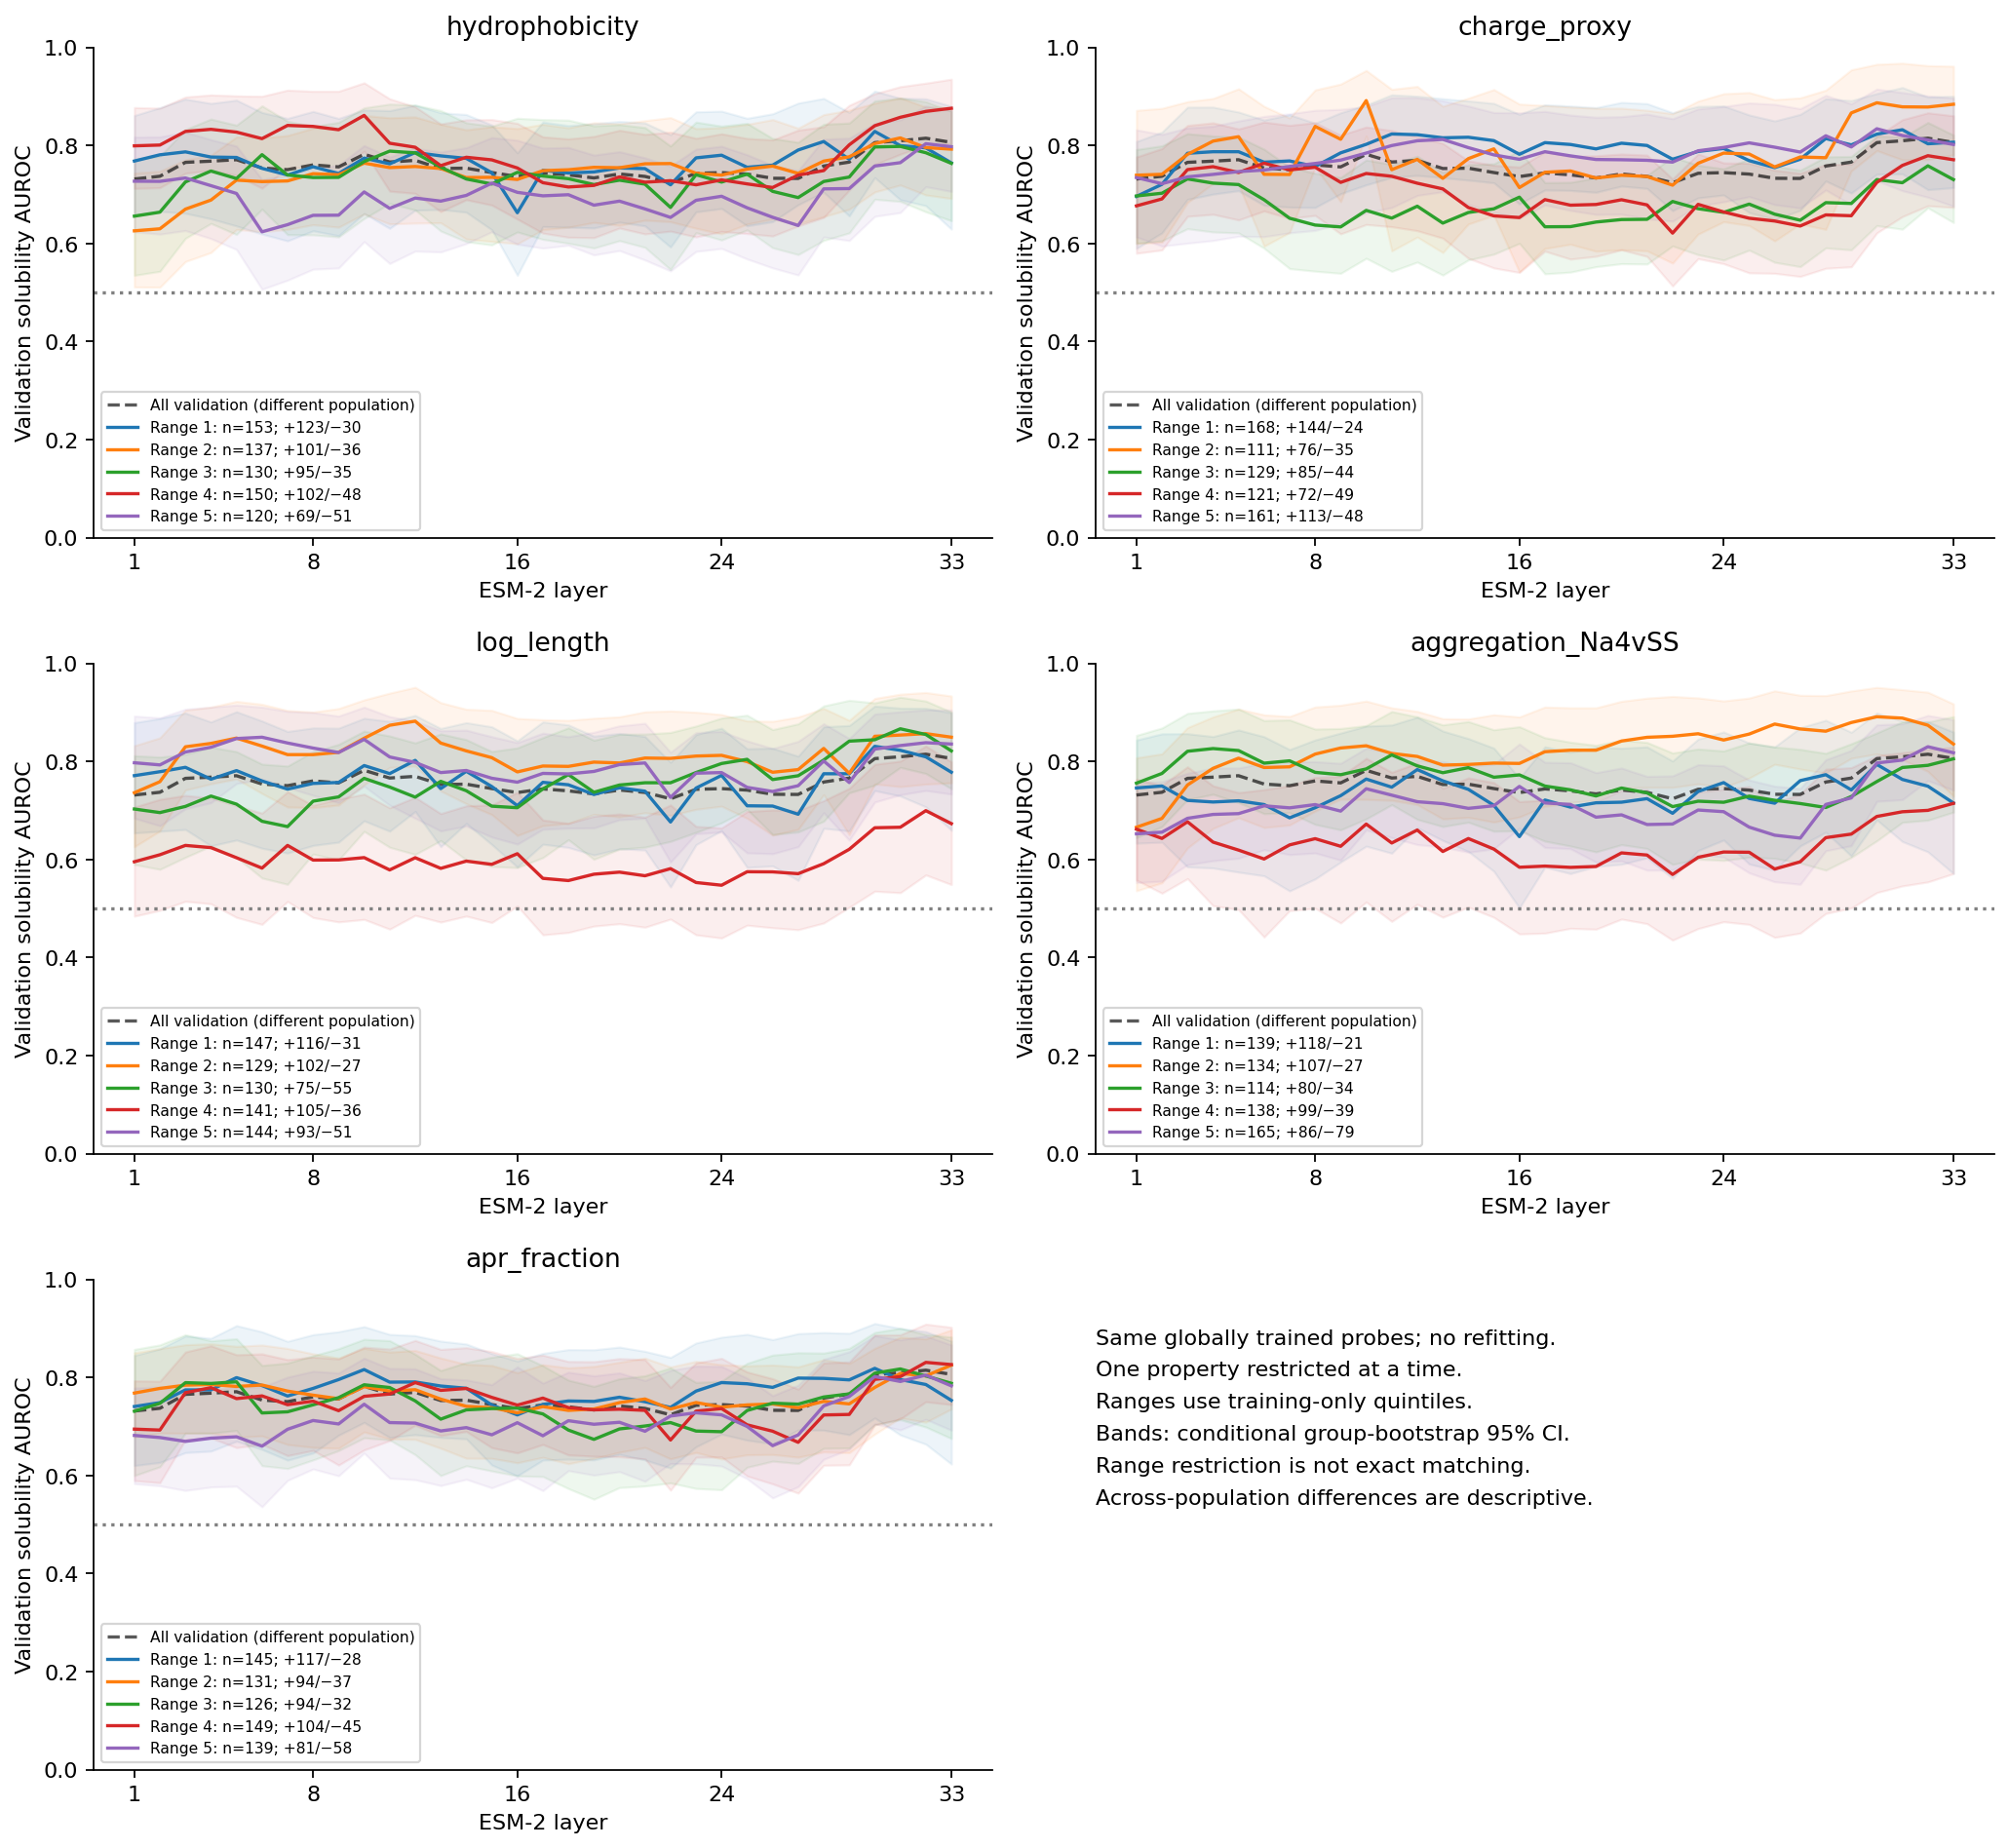

In [6]:
display(Image(filename=str(results / 'figures/solubility_within_ranges.png')))

**Interpretation:** each colored curve uses the same saved global probe on a different
validation subset. Read its soluble/insoluble counts and interval before interpreting its level or
shape. The dashed overall curve uses a different population; its difference from a range-specific
curve is descriptive. A drop can reflect reduced biological variation, changed difficulty, changed
label mix or sampling uncertainty. It is not a causal estimate of reliance on that property.

All 33 layers stay in the analysis. Choosing 4/16/32 later for a compact illustration does not require
discarding other layers. Do not choose layers solely because their restricted AUROC drops the most.

## 7. Within-family solubility and competing-assignment sensitivity

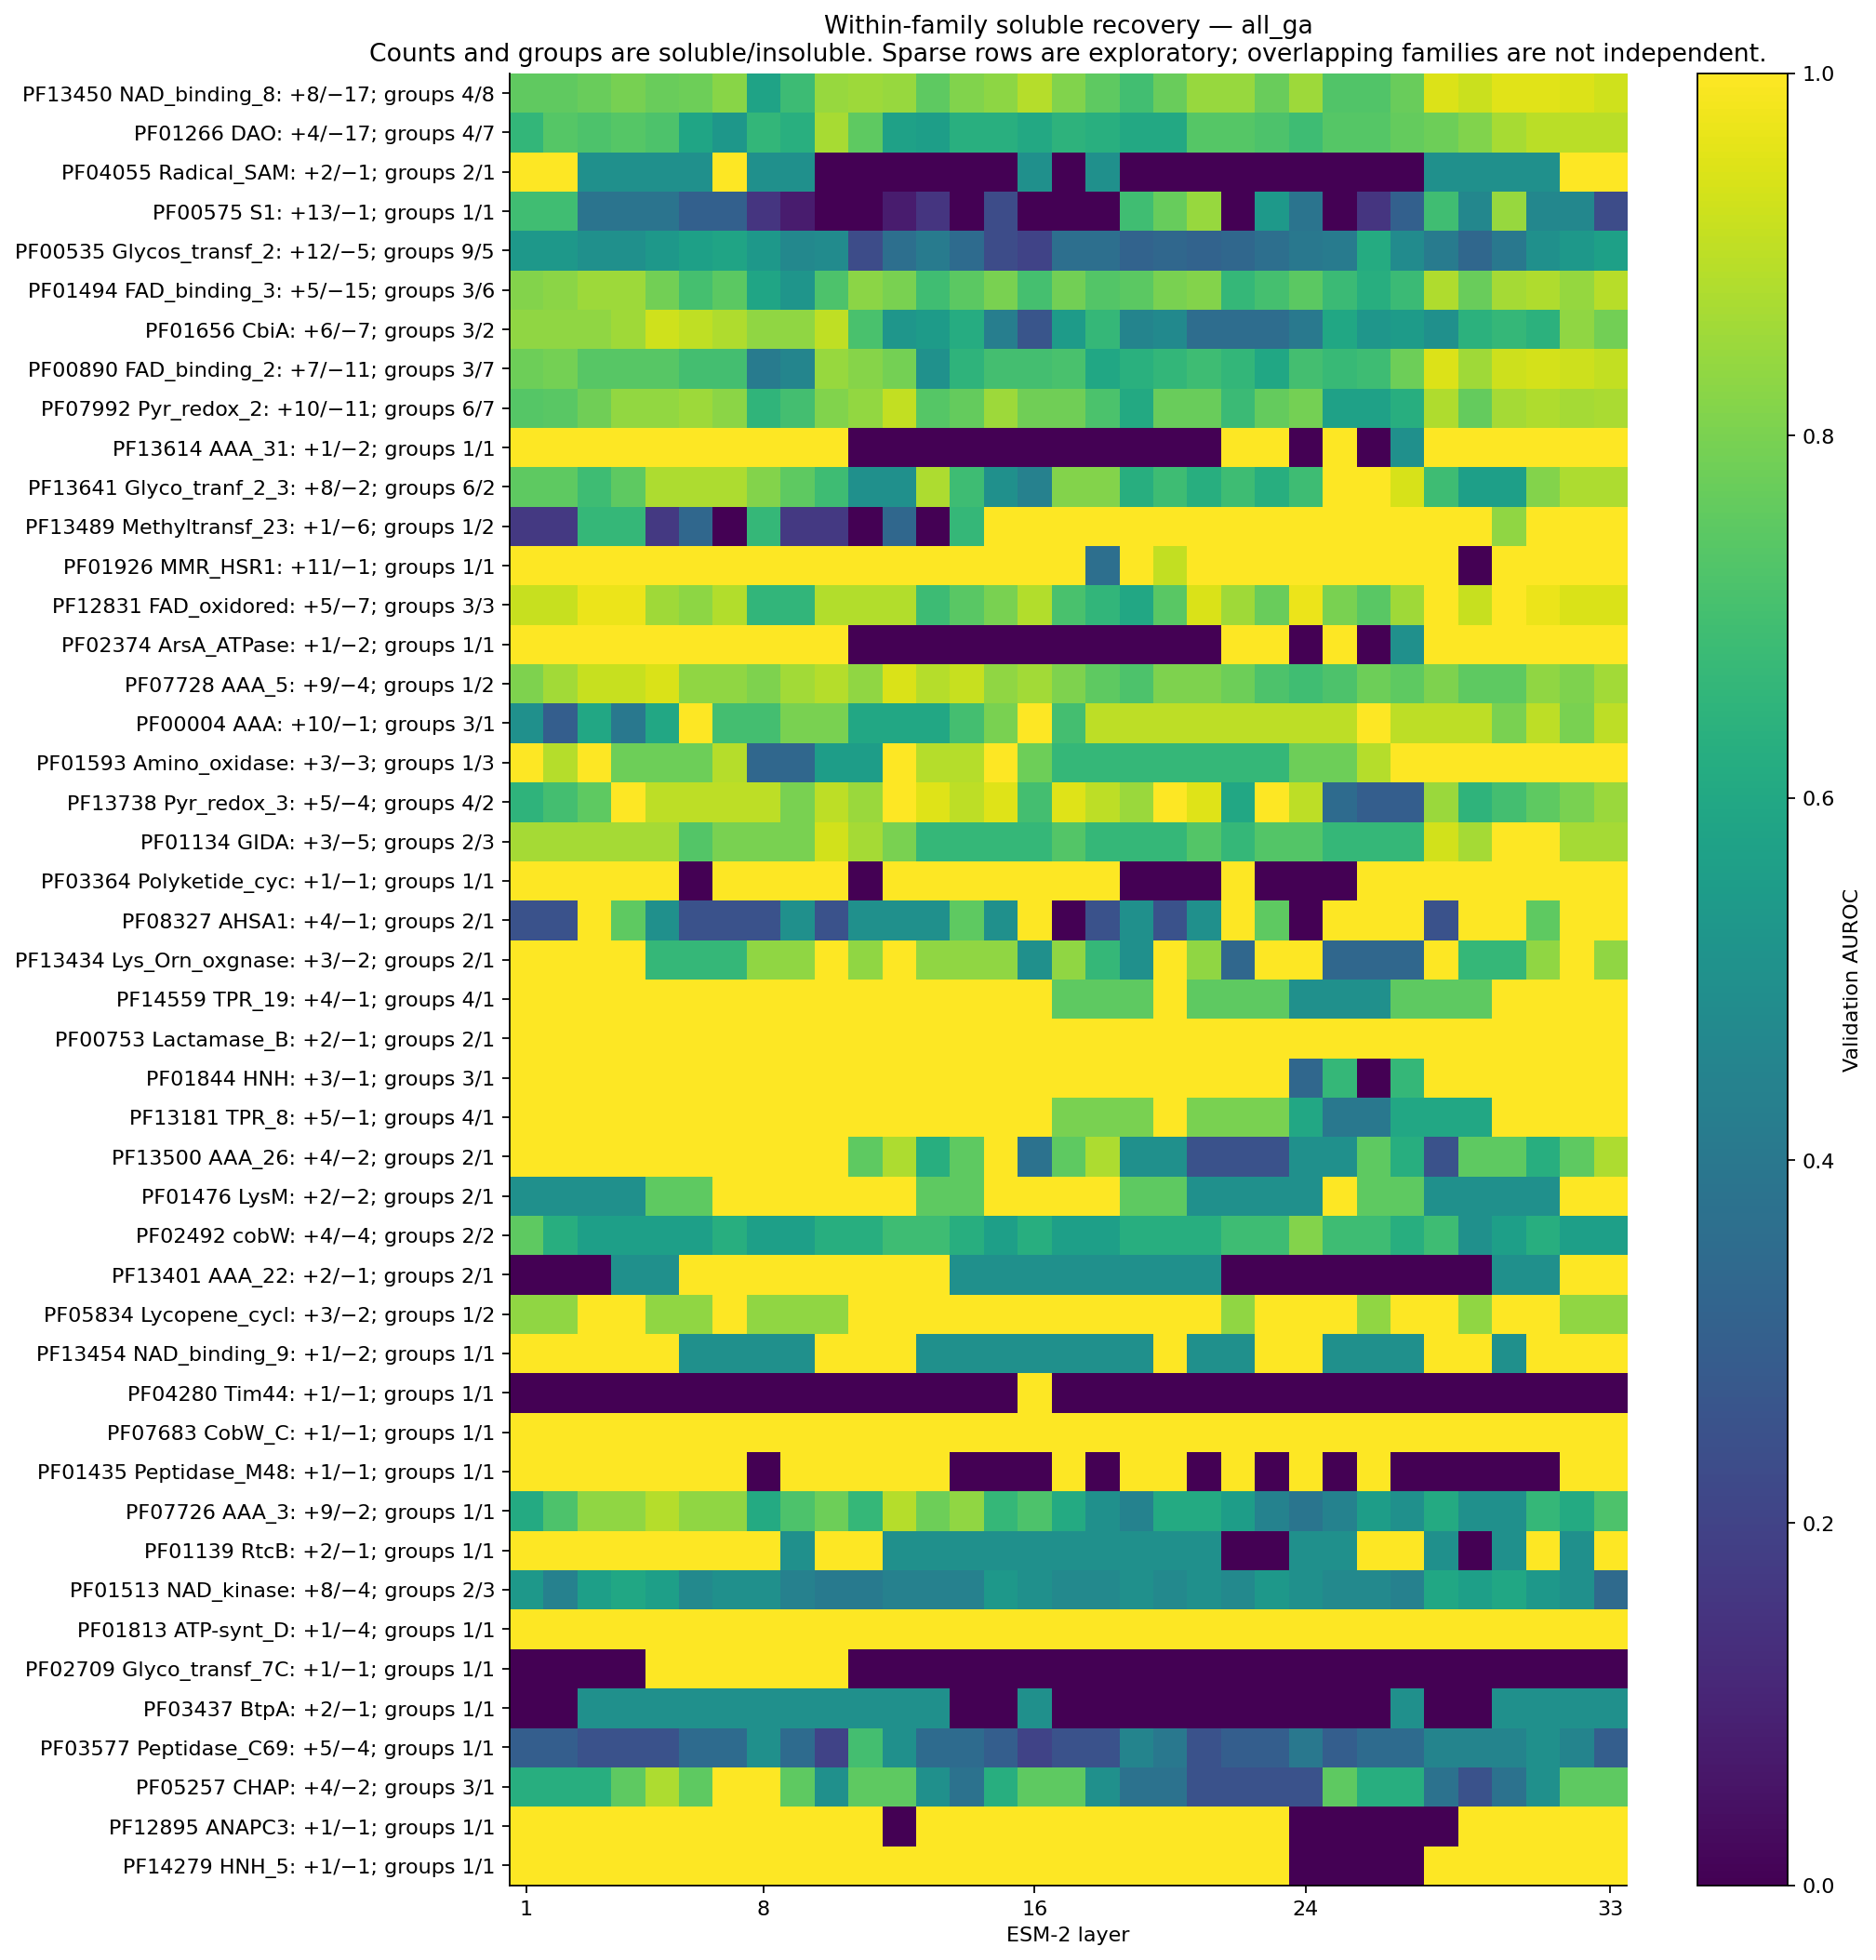

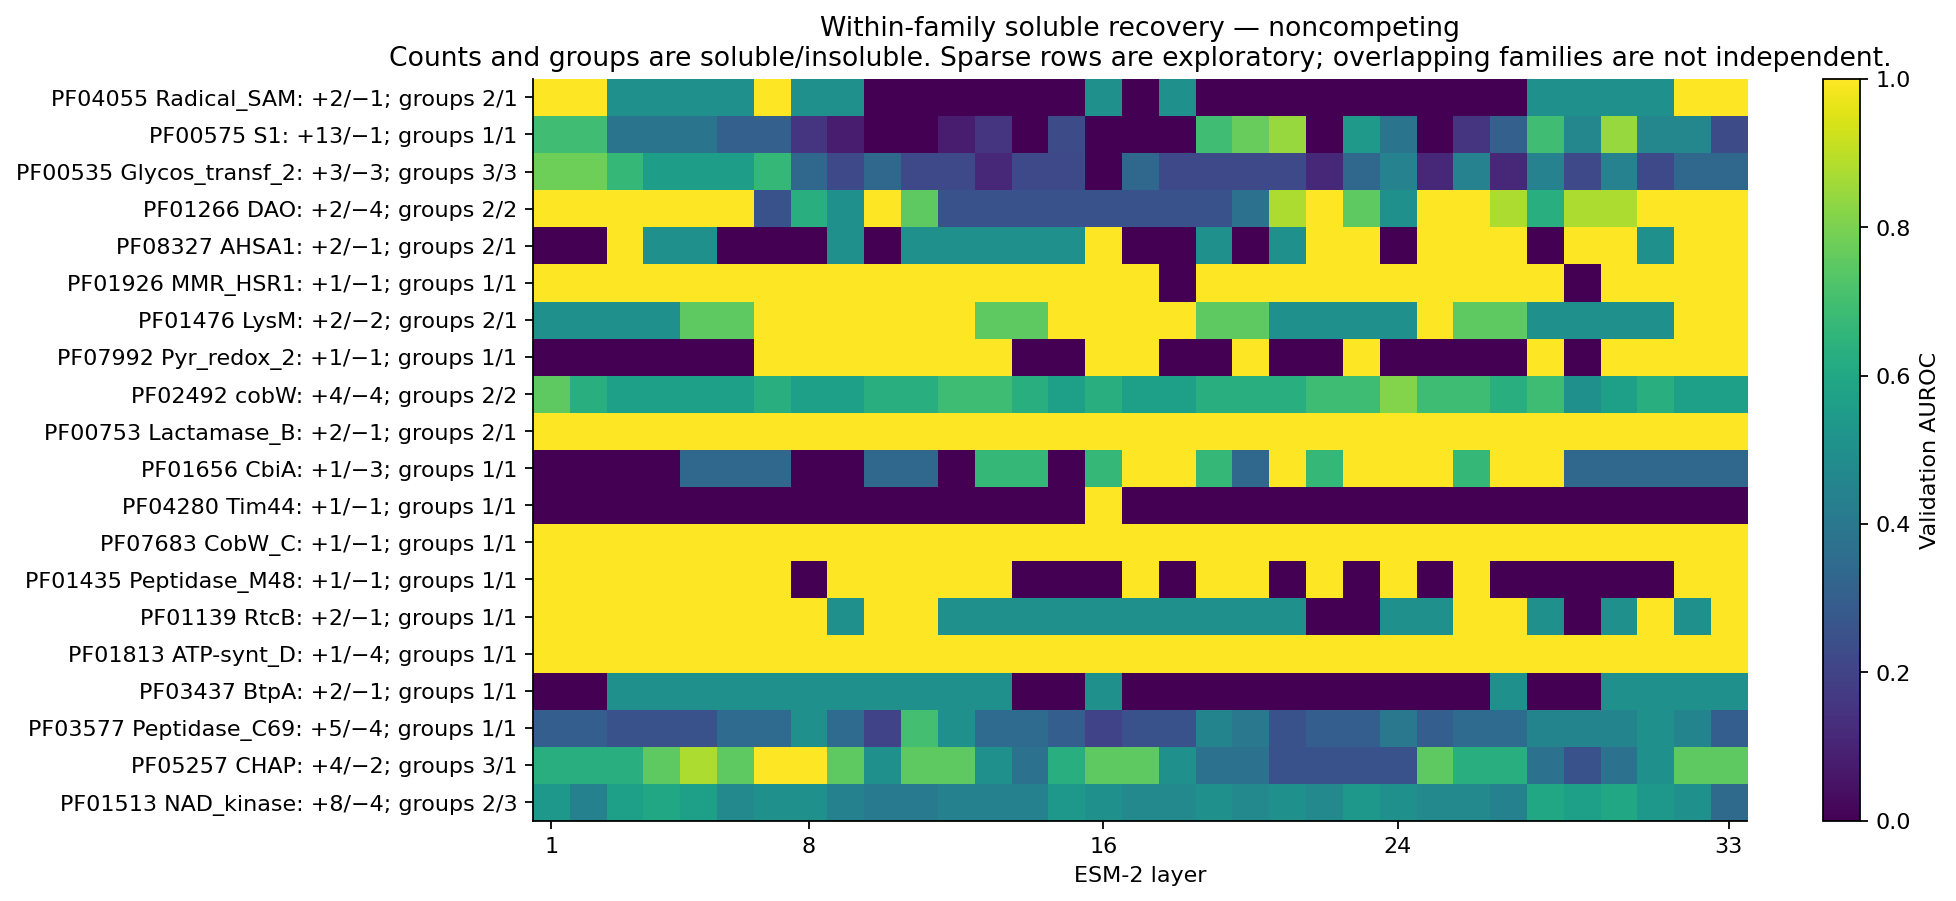

In [7]:
display(Image(filename=str(results / 'figures/solubility_within_families_all_ga.png')))
display(Image(filename=str(results / 'figures/solubility_within_families_noncompeting.png')))

**Interpretation:** family rows are separate, overlapping evaluations, not independent
replicates. One soluble and one insoluble protein can produce AUROC 0 or 1 with almost no inferential
support. The labels show protein and independent-group counts precisely to prevent treating such
rows as strong evidence. Competing-hit removal changes the evaluation population and can leave very
few contrasts. Shared Pfam membership does not establish equal architecture, organism or assay.

In [8]:
import csv, math, html
with (results / 'stratum_target_support.tsv').open() as handle:
    support_rows = list(csv.DictReader(handle, delimiter='\t'))
chosen = [r for r in support_rows if r['target']=='solubility' and r['kind']=='family' and r['status']=='estimable']
columns = ['control','category','variant','train_n','validation_n','validation_positive','positive_groups','negative_groups','ci_support_eligible']
lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
lines += ['| ' + ' | '.join(r.get(c,'') for c in columns) + ' |' for r in chosen]
display(Markdown('\n'.join(lines)))

| control | category | variant | train_n | validation_n | validation_positive | positive_groups | negative_groups | ci_support_eligible |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| PF00004 | AAA | all_ga | 17 | 11 | 10.0 | 3.0 | 1.0 | False |
| PF00535 | Glycos_transf_2 | all_ga | 48 | 17 | 12.0 | 9.0 | 5.0 | True |
| PF00535 | Glycos_transf_2 | noncompeting | 15 | 6 | 3.0 | 3.0 | 3.0 | True |
| PF00575 | S1 | all_ga | 50 | 14 | 13.0 | 1.0 | 1.0 | False |
| PF00575 | S1 | noncompeting | 50 | 14 | 13.0 | 1.0 | 1.0 | False |
| PF00753 | Lactamase_B | all_ga | 8 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF00753 | Lactamase_B | noncompeting | 3 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF00890 | FAD_binding_2 | all_ga | 40 | 18 | 7.0 | 3.0 | 7.0 | True |
| PF01134 | GIDA | all_ga | 13 | 8 | 3.0 | 2.0 | 3.0 | False |
| PF01139 | RtcB | all_ga | 1 | 3 | 2.0 | 1.0 | 1.0 | False |
| PF01139 | RtcB | noncompeting | 1 | 3 | 2.0 | 1.0 | 1.0 | False |
| PF01266 | DAO | all_ga | 62 | 21 | 4.0 | 4.0 | 7.0 | True |
| PF01266 | DAO | noncompeting | 15 | 6 | 2.0 | 2.0 | 2.0 | False |
| PF01435 | Peptidase_M48 | all_ga | 2 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF01435 | Peptidase_M48 | noncompeting | 2 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF01476 | LysM | all_ga | 6 | 4 | 2.0 | 2.0 | 1.0 | False |
| PF01476 | LysM | noncompeting | 6 | 4 | 2.0 | 2.0 | 1.0 | False |
| PF01494 | FAD_binding_3 | all_ga | 45 | 20 | 5.0 | 3.0 | 6.0 | True |
| PF01513 | NAD_kinase | all_ga | 1 | 12 | 8.0 | 2.0 | 3.0 | False |
| PF01513 | NAD_kinase | noncompeting | 0 | 12 | 8.0 | 2.0 | 3.0 | False |
| PF01593 | Amino_oxidase | all_ga | 15 | 6 | 3.0 | 1.0 | 3.0 | False |
| PF01656 | CbiA | all_ga | 42 | 13 | 6.0 | 3.0 | 2.0 | False |
| PF01656 | CbiA | noncompeting | 3 | 4 | 1.0 | 1.0 | 1.0 | False |
| PF01813 | ATP-synt_D | all_ga | 1 | 5 | 1.0 | 1.0 | 1.0 | False |
| PF01813 | ATP-synt_D | noncompeting | 1 | 5 | 1.0 | 1.0 | 1.0 | False |
| PF01844 | HNH | all_ga | 8 | 4 | 3.0 | 3.0 | 1.0 | False |
| PF01926 | MMR_HSR1 | all_ga | 24 | 12 | 11.0 | 1.0 | 1.0 | False |
| PF01926 | MMR_HSR1 | noncompeting | 8 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF02374 | ArsA_ATPase | all_ga | 20 | 3 | 1.0 | 1.0 | 1.0 | False |
| PF02492 | cobW | all_ga | 5 | 8 | 4.0 | 2.0 | 2.0 | False |
| PF02492 | cobW | noncompeting | 5 | 8 | 4.0 | 2.0 | 2.0 | False |
| PF02709 | Glyco_transf_7C | all_ga | 1 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF03364 | Polyketide_cyc | all_ga | 13 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF03437 | BtpA | all_ga | 1 | 3 | 2.0 | 1.0 | 1.0 | False |
| PF03437 | BtpA | noncompeting | 1 | 3 | 2.0 | 1.0 | 1.0 | False |
| PF03577 | Peptidase_C69 | all_ga | 1 | 9 | 5.0 | 1.0 | 1.0 | False |
| PF03577 | Peptidase_C69 | noncompeting | 1 | 9 | 5.0 | 1.0 | 1.0 | False |
| PF04055 | Radical_SAM | all_ga | 52 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF04055 | Radical_SAM | noncompeting | 52 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF04280 | Tim44 | all_ga | 3 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF04280 | Tim44 | noncompeting | 3 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF05257 | CHAP | all_ga | 1 | 6 | 4.0 | 3.0 | 1.0 | False |
| PF05257 | CHAP | noncompeting | 1 | 6 | 4.0 | 3.0 | 1.0 | False |
| PF05834 | Lycopene_cycl | all_ga | 4 | 5 | 3.0 | 1.0 | 2.0 | False |
| PF07683 | CobW_C | all_ga | 3 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF07683 | CobW_C | noncompeting | 3 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF07726 | AAA_3 | all_ga | 2 | 11 | 9.0 | 1.0 | 1.0 | False |
| PF07728 | AAA_5 | all_ga | 19 | 13 | 9.0 | 1.0 | 2.0 | False |
| PF07992 | Pyr_redox_2 | all_ga | 32 | 21 | 10.0 | 6.0 | 7.0 | True |
| PF07992 | Pyr_redox_2 | noncompeting | 6 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF08327 | AHSA1 | all_ga | 12 | 5 | 4.0 | 2.0 | 1.0 | False |
| PF08327 | AHSA1 | noncompeting | 12 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF12831 | FAD_oxidored | all_ga | 21 | 12 | 5.0 | 3.0 | 3.0 | True |
| PF12895 | ANAPC3 | all_ga | 1 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF13181 | TPR_8 | all_ga | 8 | 6 | 5.0 | 4.0 | 1.0 | False |
| PF13401 | AAA_22 | all_ga | 5 | 3 | 2.0 | 2.0 | 1.0 | False |
| PF13434 | Lys_Orn_oxgnase | all_ga | 12 | 5 | 3.0 | 2.0 | 1.0 | False |
| PF13450 | NAD_binding_8 | all_ga | 69 | 25 | 8.0 | 4.0 | 8.0 | True |
| PF13454 | NAD_binding_9 | all_ga | 4 | 3 | 1.0 | 1.0 | 1.0 | False |
| PF13489 | Methyltransf_23 | all_ga | 26 | 7 | 1.0 | 1.0 | 2.0 | False |
| PF13500 | AAA_26 | all_ga | 7 | 6 | 4.0 | 2.0 | 1.0 | False |
| PF13614 | AAA_31 | all_ga | 30 | 3 | 1.0 | 1.0 | 1.0 | False |
| PF13641 | Glyco_tranf_2_3 | all_ga | 30 | 10 | 8.0 | 6.0 | 2.0 | False |
| PF13738 | Pyr_redox_3 | all_ga | 14 | 9 | 5.0 | 4.0 | 2.0 | False |
| PF14279 | HNH_5 | all_ga | 1 | 2 | 1.0 | 1.0 | 1.0 | False |
| PF14559 | TPR_19 | all_ga | 9 | 5 | 4.0 | 4.0 | 1.0 | False |

## 8. Other properties within ranges

These panels use continuous-target R², not AUROC. Full MAE/RMSE results and within-family continuous
results are in the exact-result viewer below. Family-membership AUROC/AP inside numeric ranges is
also available there. The subset definitions are identical across layers for each target.

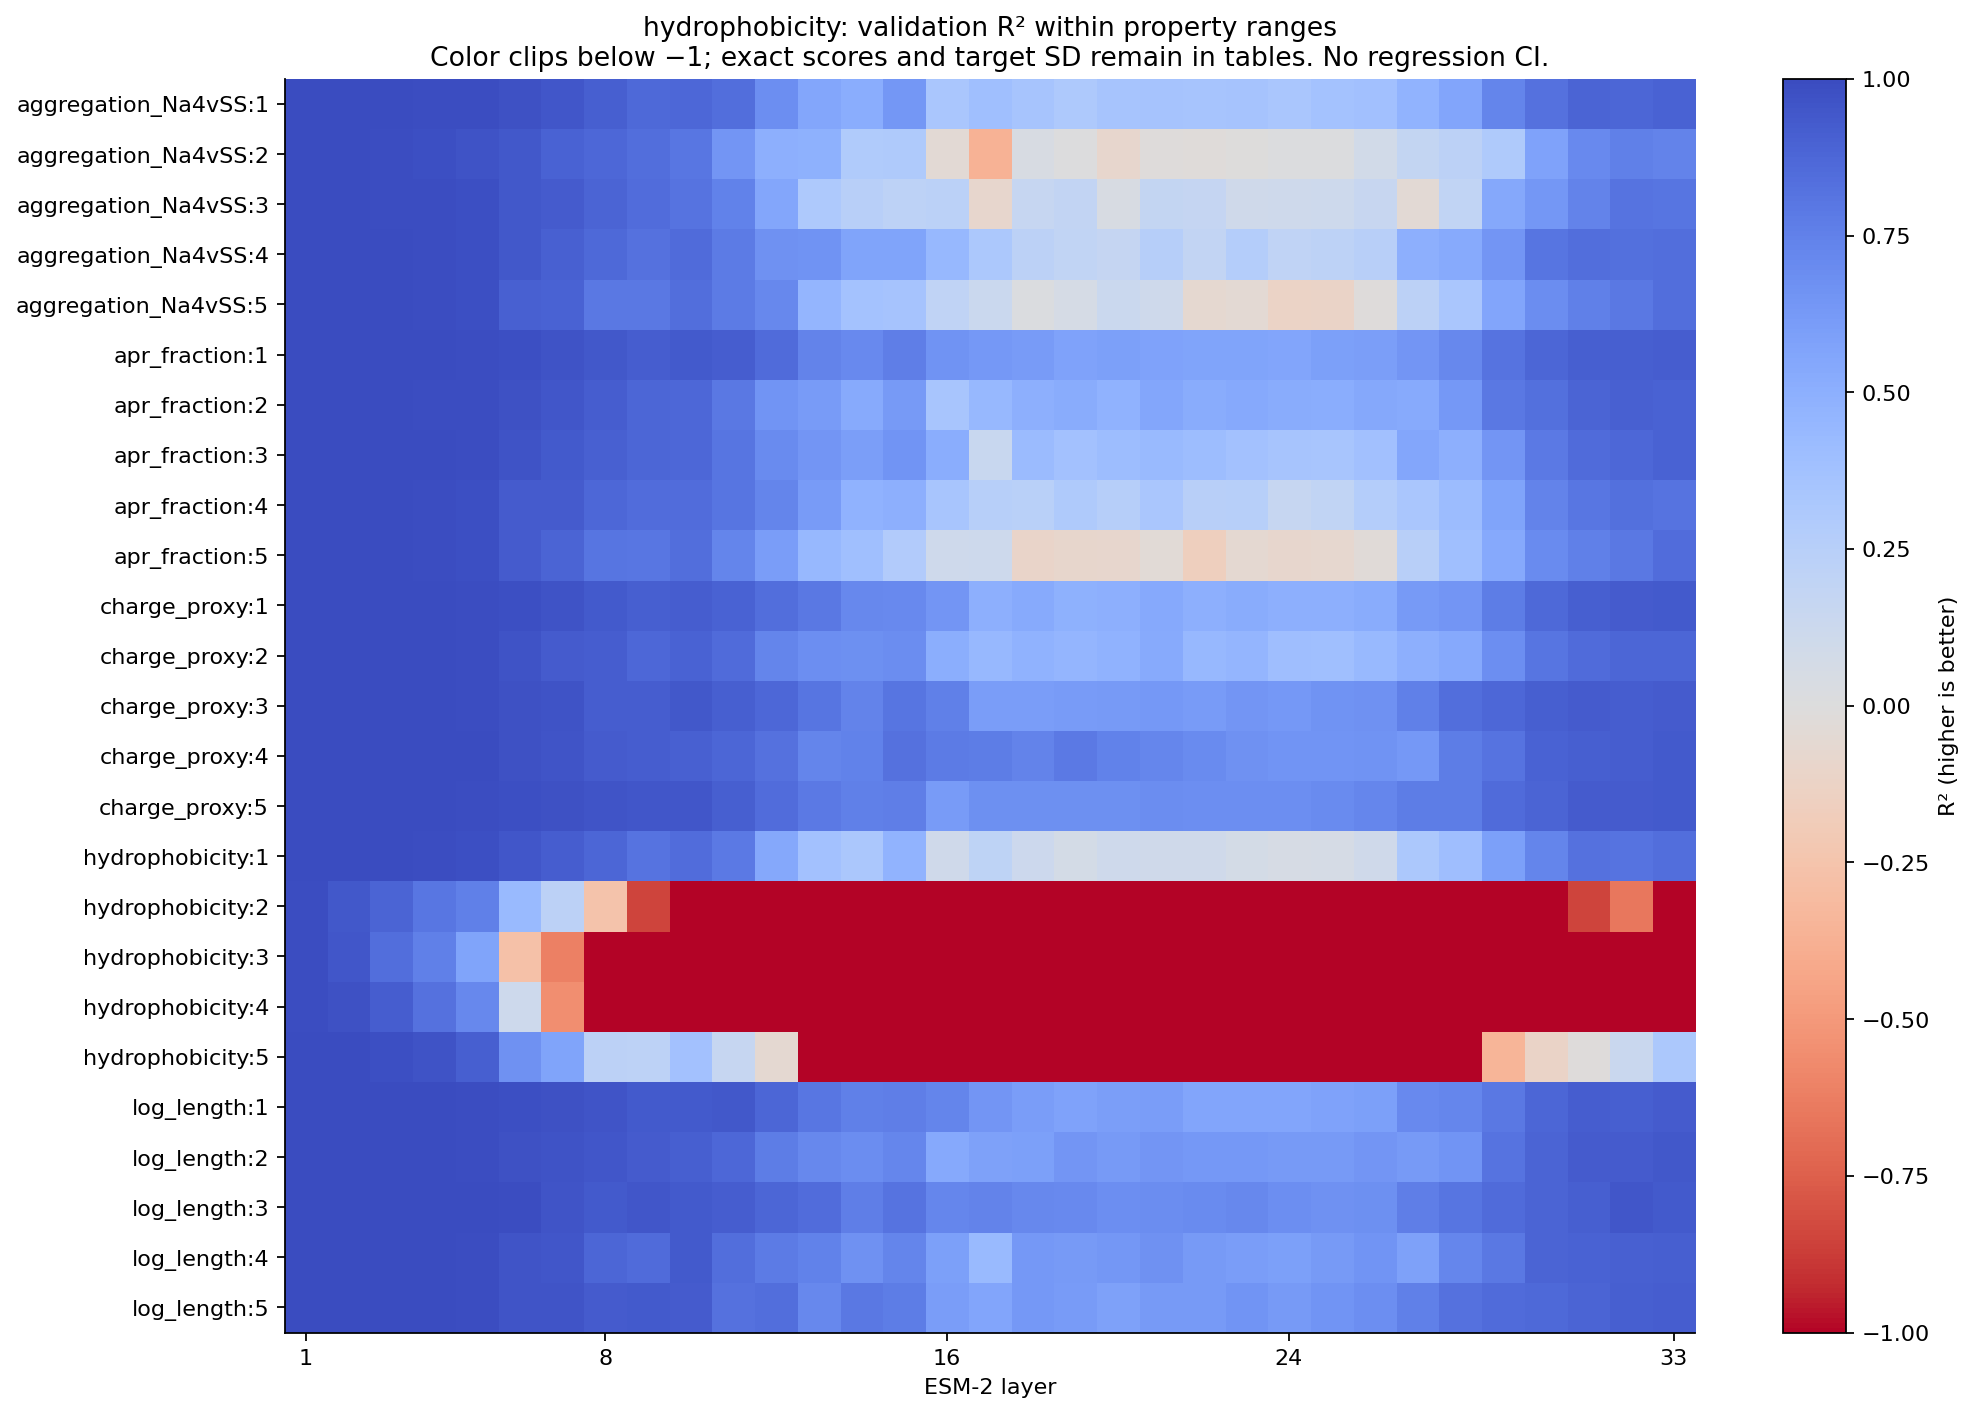

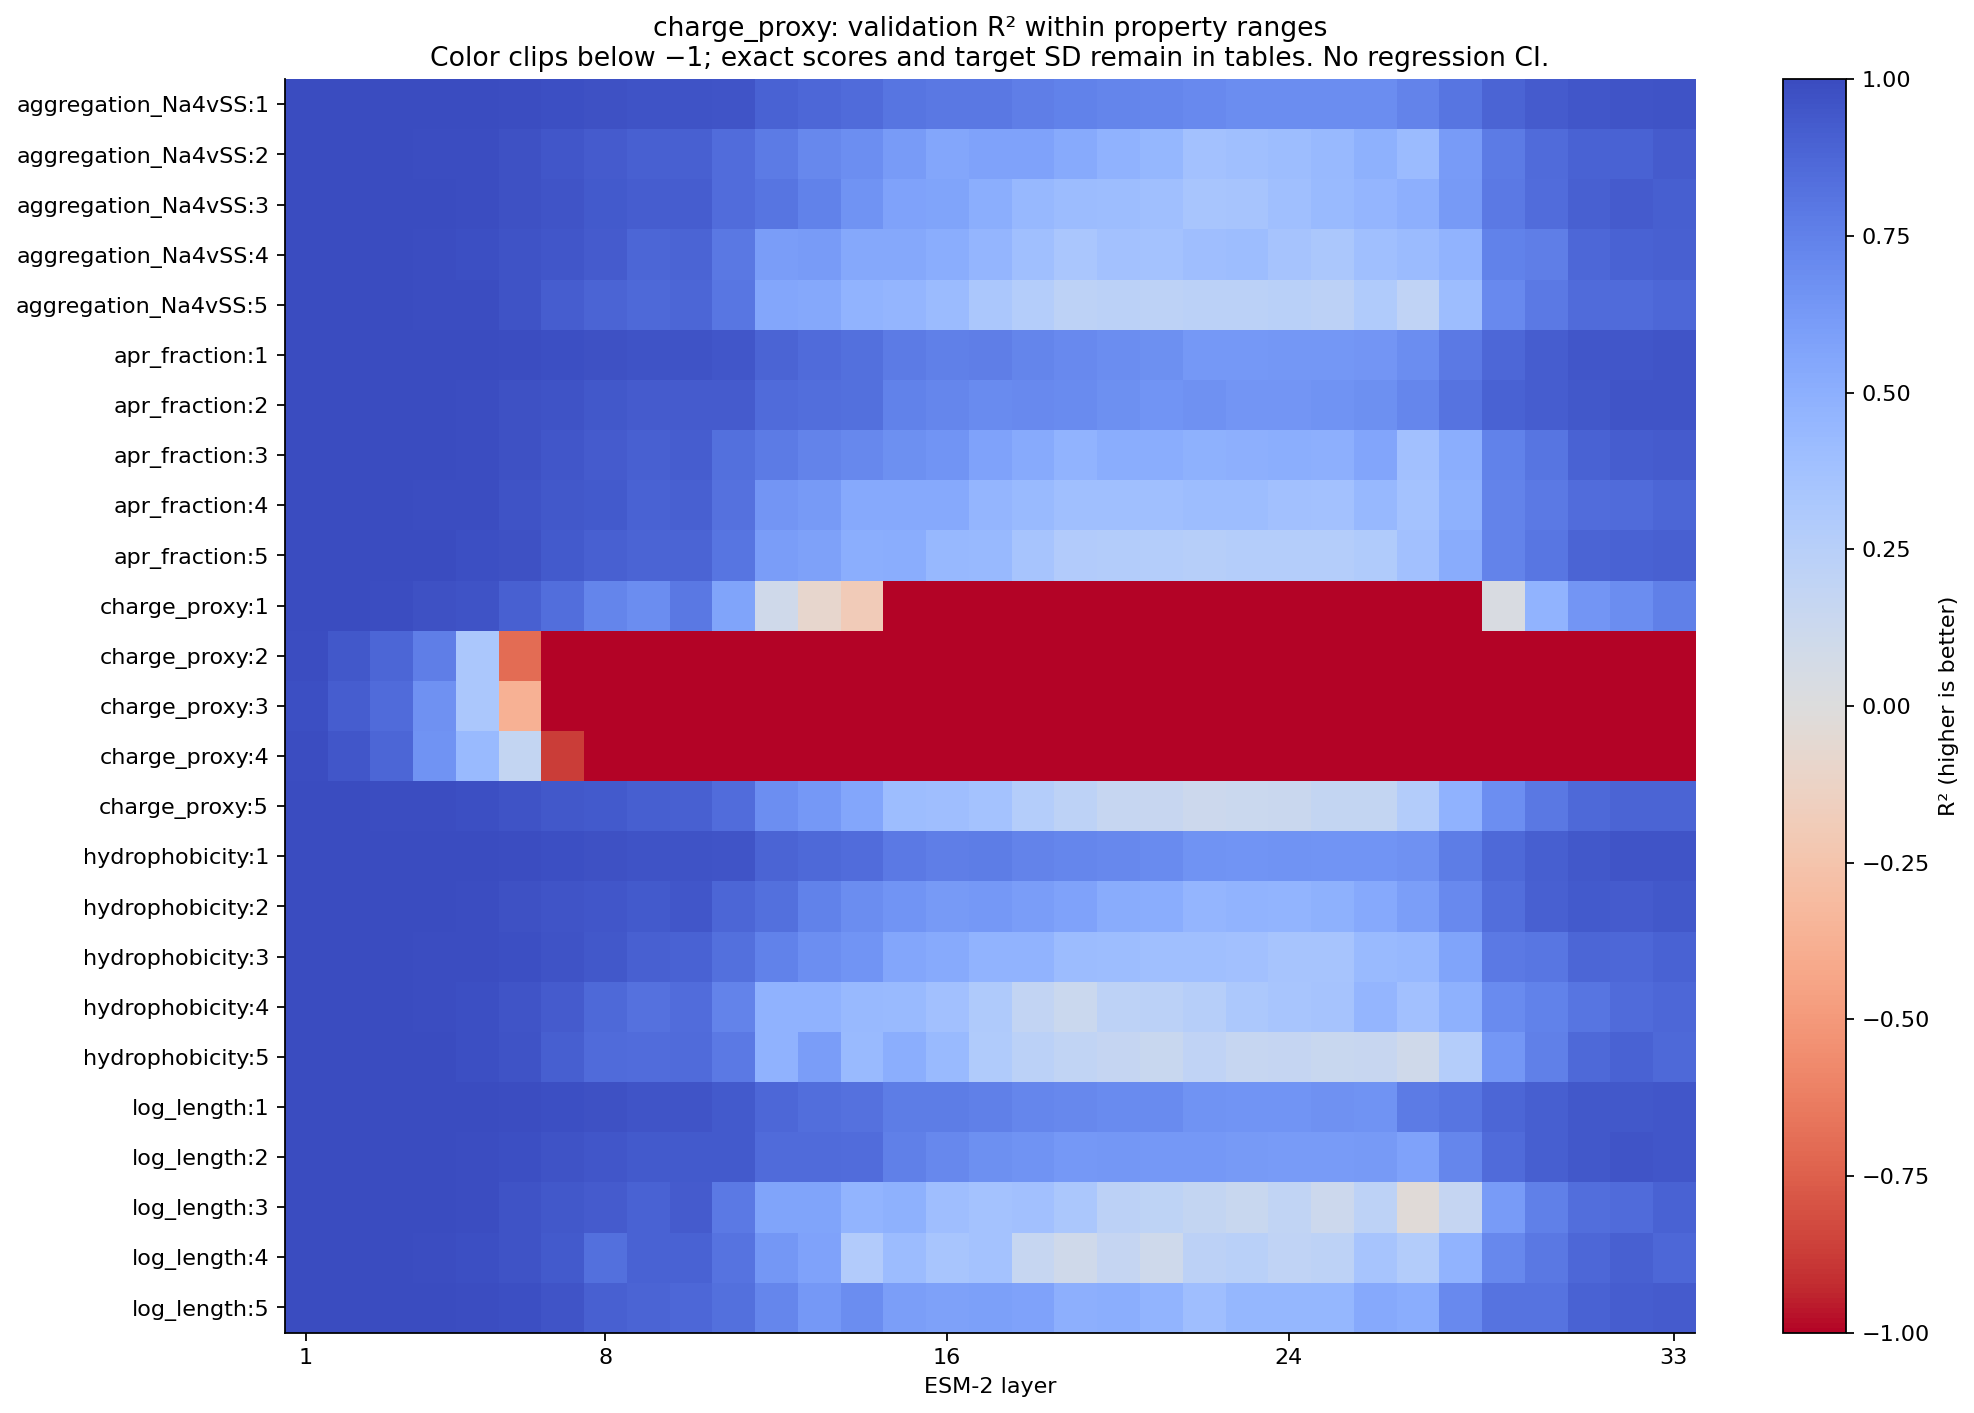

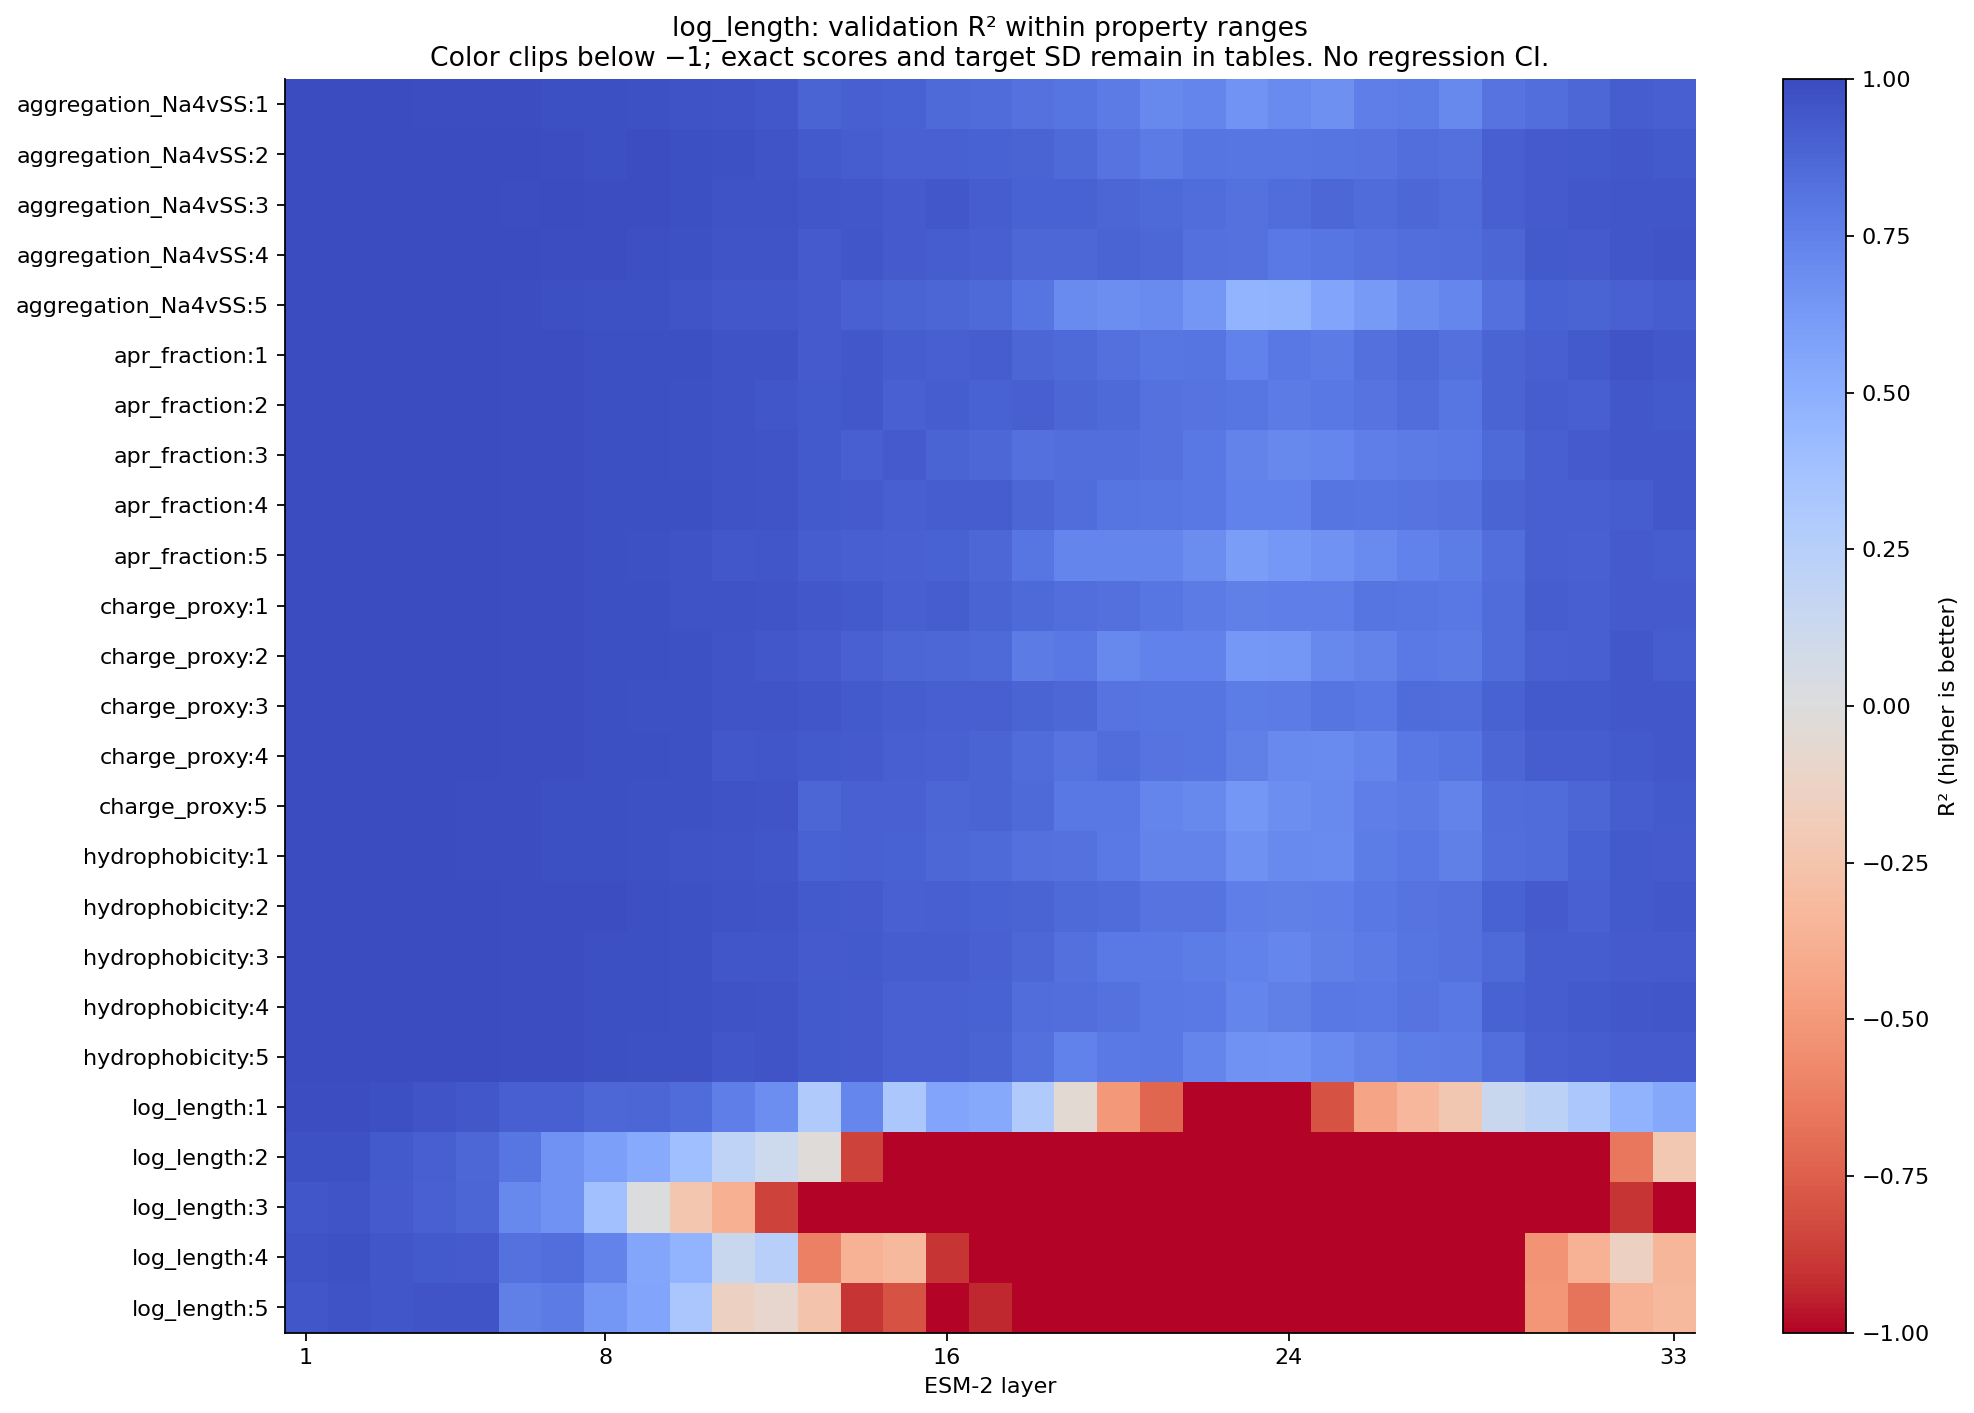

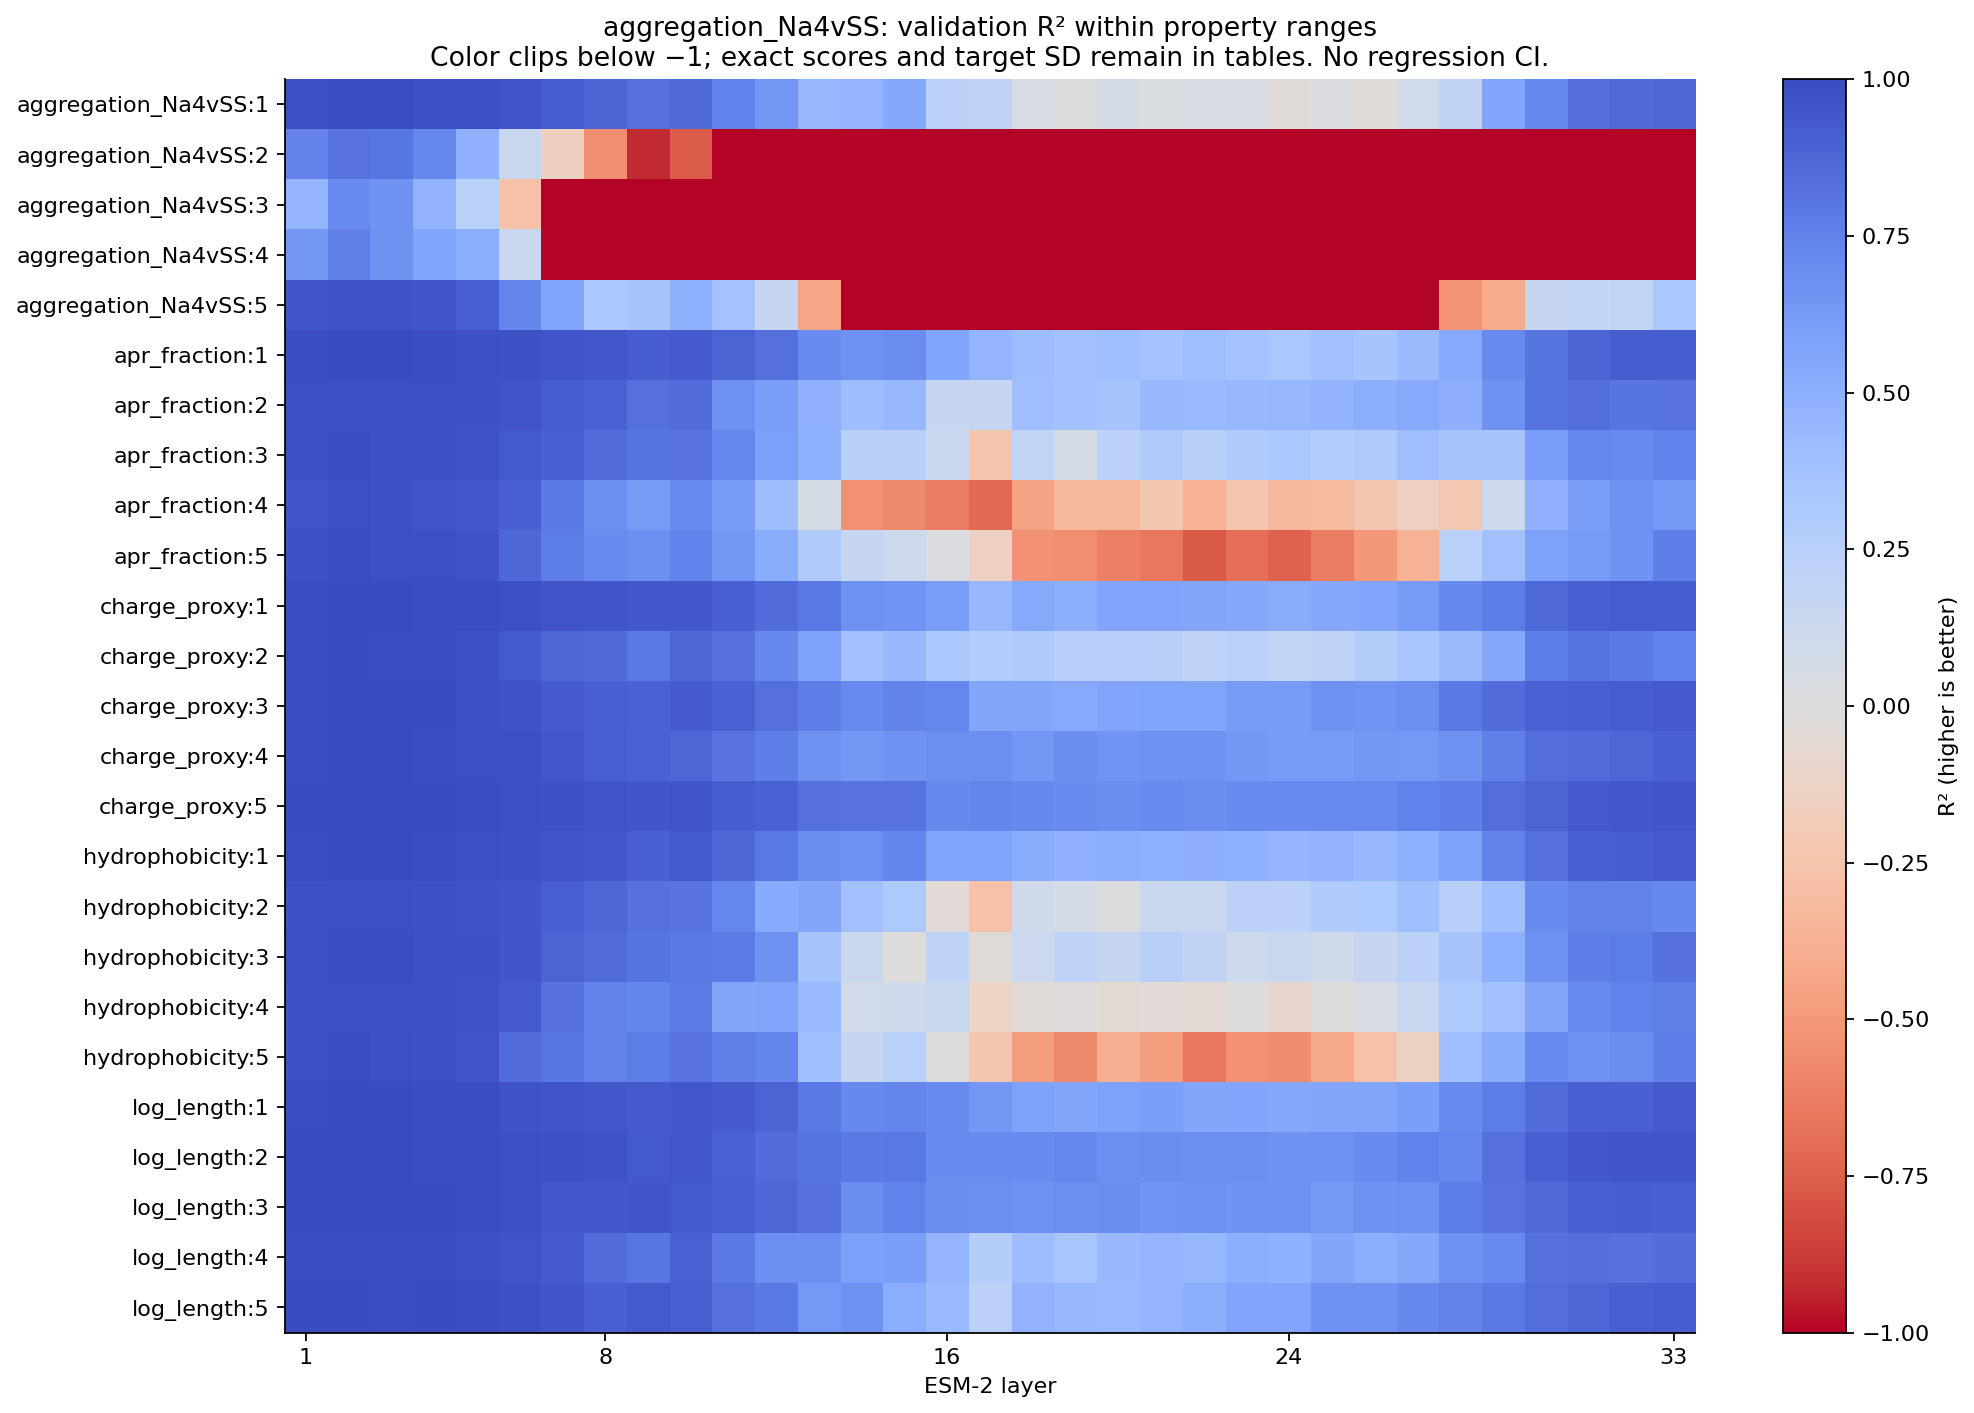

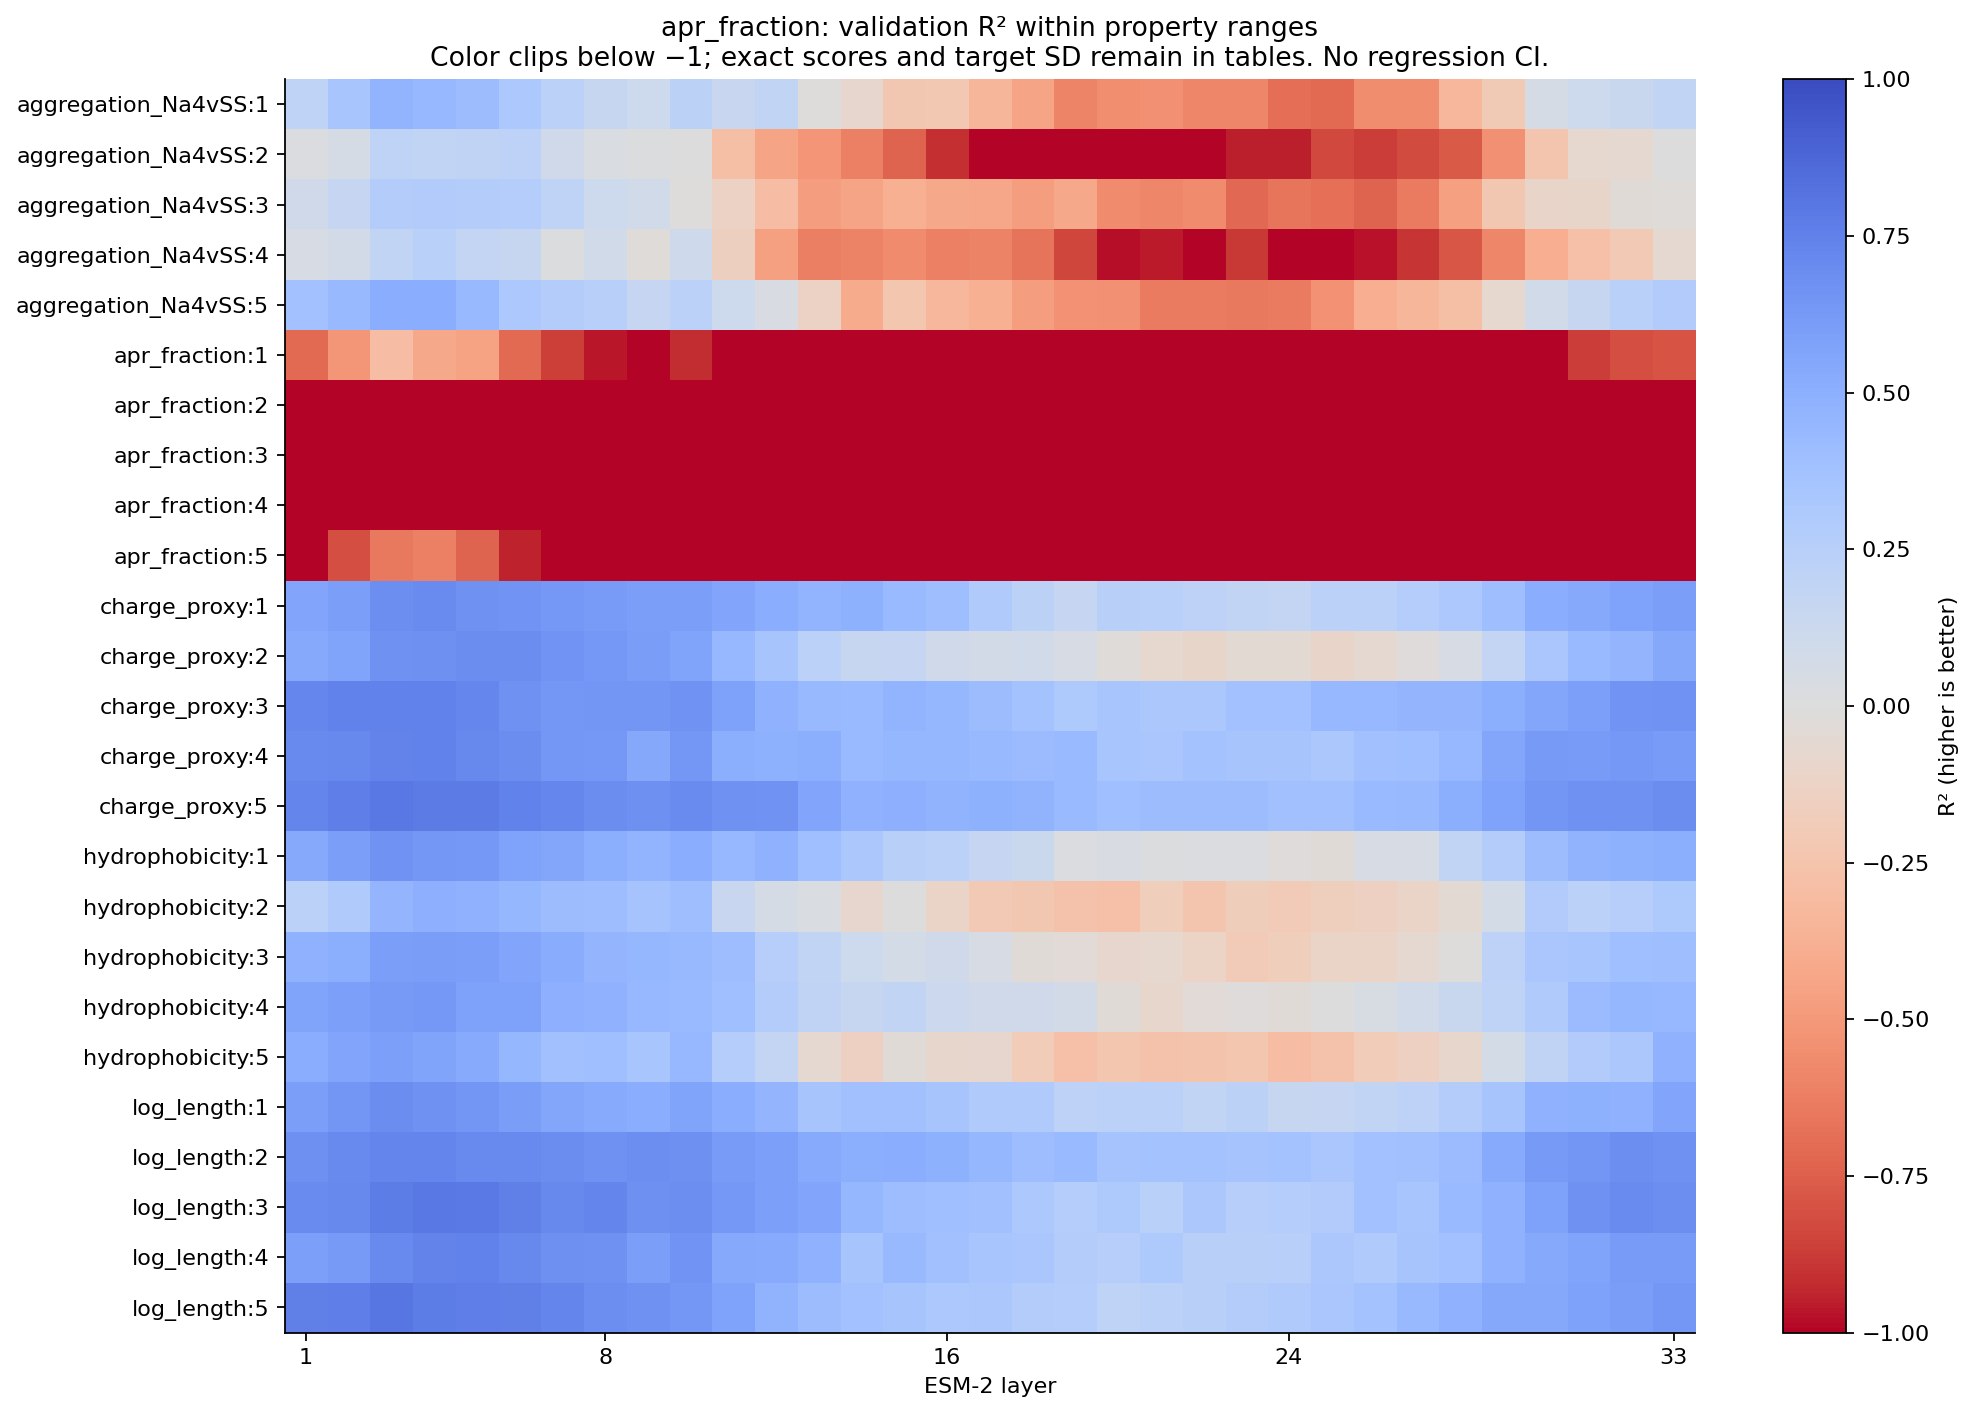

In [9]:
for name in ['hydrophobicity','charge_proxy','log_length','aggregation_Na4vSS','apr_fraction']:
    display(Image(filename=str(results / f'figures/secondary_{name}.png')))

**Interpretation:** restricting the property being predicted reduces target variance,
which can sharply reduce R² even if absolute error changes little. Inspect target SD and MAE together.
Constant targets have undefined R², not a meaningful failure to decode. Hydropathy, charge and length
are deterministic descriptors; AGGRESCAN outputs are predictions rather than aggregation measurements.
These secondary point estimates have no confidence bands and are exploratory.

## 9. Exact results for any target/subset

Change the two display strings below and rerun **only this cell** to inspect a different subset.
Examples: `range:hydrophobicity:1`, `range:aggregation_Na4vSS:3`, `family:PF04055:all_ga`,
`family:PF04055:noncompeting`, or `overall`. `TARGET` can be `solubility`, one of the five continuous
target names, or an eligible Pfam accession for numeric-range evaluation. This changes the display only.

In [10]:
TARGET = 'solubility'
STRATUM = 'range:hydrophobicity:3'
with (results / 'within_property_metrics.tsv').open() as handle:
    rows = [r for r in csv.DictReader(handle, delimiter='\t') if r['target']==TARGET and r['key']==STRATUM]
if not rows:
    print('No evaluated task for this combination. Check stratum_target_support.tsv; family-membership targets are evaluated only in numeric ranges.')
else:
    first = rows[0]
    display(Markdown(f"**{TARGET} / {STRATUM}** — validation N={first['validation_n']}; groups={first['validation_groups']}; target SD={first['validation_target_sd']}; status={first['status']}"))
    columns = ['layer','metric','value','low','high','composition','delta_vs_composition','delta_low','delta_high','bootstrap_valid']
    def formatted(value):
        try:
            v=float(value)
            return f'{v:.4f}' if math.isfinite(v) else 'undefined'
        except (ValueError,TypeError):
            return value or 'undefined'
    body='<tr>'+''.join('<th>'+html.escape(c)+'</th>' for c in columns)+'</tr>'
    for row in rows:
        body+='<tr>'+''.join('<td>'+html.escape(formatted(row[c]))+'</td>' for c in columns)+'</tr>'
    display(HTML('<div style="max-height:600px;overflow:auto"><table>'+body+'</table></div>'))

**solubility / range:hydrophobicity:3** — validation N=130; groups=90; target SD=0.4435600997950306; status=estimable

layer,metric,value,low,high,composition,delta_vs_composition,delta_low,delta_high,bootstrap_valid
0.0000,auroc,0.6698,0.5396,0.7877,0.6698,0.0000,0.0000,0.0000,2000.0000
0.0000,average_precision,0.8402,0.7291,0.9297,0.8402,0.0000,0.0000,0.0000,2000.0000
1.0000,auroc,0.6556,0.5350,0.7716,0.6698,-0.0141,-0.0824,0.0548,2000.0000
1.0000,average_precision,0.8397,0.7352,0.9252,0.8402,-0.0005,-0.0395,0.0381,2000.0000
2.0000,auroc,0.6638,0.5432,0.7780,0.6698,-0.0060,-0.0789,0.0671,2000.0000
2.0000,average_precision,0.8463,0.7404,0.9301,0.8402,0.0061,-0.0286,0.0447,2000.0000
3.0000,auroc,0.7254,0.6105,0.8325,0.6698,0.0556,-0.0303,0.1473,2000.0000
3.0000,average_precision,0.8777,0.7820,0.9491,0.8402,0.0375,-0.0027,0.0867,2000.0000
4.0000,auroc,0.7477,0.6408,0.8537,0.6698,0.0779,-0.0180,0.1809,2000.0000
4.0000,average_precision,0.8870,0.8000,0.9550,0.8402,0.0468,0.0015,0.1016,2000.0000


## 10. Saved report and boundaries of the analysis

In [11]:
display(Markdown((results / 'WITHIN_PROPERTY_RESULTS.md').read_text()))
url=f"https://huggingface.co/datasets/{latest['repository']}/tree/main/{latest['hf_prefix']}"
display(Markdown(f'[Private HF evaluation results]({url}) — `results.zip` contains the complete tables, protocol, source hashes and PNG/SVG figures.'))

# Within-property evaluation

These results evaluate the same globally trained probes at all 33 layers on fixed validation subsets. There was no fitting, ESM inference, layer selection or reserved-test access. Layer 00 is the existing composition baseline, not the ESM embedding layer.

Numeric strata use observed training quintiles with tied boundaries collapsed and unbounded outer intervals. They restrict one descriptor at a time; they do not hold that descriptor exactly constant or control all other properties. Missing descriptors remain missing. Family strata retain multiple GA-passing memberships, with noncompeting-assignment results reported separately on their own populations. Domain membership does not guarantee matched architecture, organism or assay.

Every family observed in training is included in the support table. Families with at least two validation proteins receive point estimates where the target varies. Single-class binary targets have undefined AUROC/AP; constant continuous targets have undefined R². Small families may give extreme AUROC values by chance. These strata are not new training datasets. The defining family is not predicted within itself.

Solubility intervals resample validation homology groups and are conditional on the saved probes. They require ≥3 groups per label and ≥90% valid draws; these are reporting safeguards, not proof of adequate confirmatory power. Secondary targets have point estimates only. Exact target range and SD accompany regression results because range restriction changes R². Existing family-membership probes are assessed within numeric ranges only; other properties are also assessed within families.

`within_property_metrics.tsv` contains all targets, layers, strata, support and metrics. `delta_vs_composition` and its interval compare models on identical proteins within a stratum. Overall-versus-stratum curves use different populations and are descriptive, not paired treatment effects or causal evidence of confounding. No families are pooled into a duplicated protein population. Plotting many strata/layers is exploratory; the largest drop is not a prespecified finding.

Training counts describe support. Performance here is fixed-validation performance; training probes are unchanged. Review uncontrolled results first, then these evaluations. Choosing a few layers may simplify a slide, but all 33 remain the primary analysis.


[Private HF evaluation results](https://huggingface.co/datasets/PLM-Interp/nesg-esm2-layerwise/tree/main/esm_stage1/within_property_evaluation_v1/822e96332bf093cc5c66f9b6bfd5f2e0e6f6184badbd6cfe1002fdc21160fdcd) — `results.zip` contains the complete tables, protocol, source hashes and PNG/SVG figures.

Keep the complete layer-wise curves as the primary descriptive result. Small differences
or the largest observed drop across many restrictions need uncertainty and multiplicity caution.
This notebook does not establish a direct solubility representation or a causal computation.
Mechanistic hypotheses and SAE interventions remain separate subsequent work.